# 03 · CRECl classes and homology (Figs 1D, 1E)

Classifies the CRECls of notebook 01, summarises their accessibility over the 40 states of notebook 02, pairs mouse and
rabbit CRECls by their accessibility over the 24 homologous states, and draws Figs 1D and 1E.

1. **CRECl profiles**: mean accessibility of each CRECl in each SMC / metacell.
2. **Classes**: pan-gastrulation, weak and small CRECls; the rest (83 mouse, 85 rabbit) are variable.
3. **Accessibility by state**: ATAC UMIs of each CRECl summed per state, as log2 of the fraction of the CRECl's UMIs
   (used by Figs 1E, 2A and 4A).
4. **Anchor pairs**: mouse and rabbit variable CRECls that are each other's best correlated over the 24 homologous
   states; 33 pairs.
5. **Numbering**: each other CRECl joins the anchor whose profile (step 1) it correlates with best; anchors are numbered
   1-33 in the paper's order and the others k.1, k.2, ... by decreasing correlation.
6. **Fig 1D**: accessibility of the pdCREs of the 15 ontogenic and 18 combinatorial anchor CRECls in the SMCs and
   metacells.
7. **Fig 1E**: accessibility of four ontogenic and four combinatorial anchor pairs over the 24 homologous states.

## Setup

In [1]:
source("../R/setup.R")
source("../R/cell_types.R")
suppressPackageStartupMessages(library(zoo))
out_dir = out_path("03_crecl_homology")
O1 = file.path(OUT_DIR, "01_crecls")
O2 = file.path(OUT_DIR, "02_states")
mm_km = list(cluster = with(fread(file.path(O1, "mm_crecl.csv")), setNames(kmc, locid)))
oc_km = list(cluster = with(fread(file.path(O1, "oc_crecl.csv")), setNames(kmc, locid)))
acc = readRDS(file.path(O1, "accessibility.rds"))
mm_a_legc = acc$mm_a_legc
oc_a_legc = acc$oc_a_legc
umis = readRDS(file.path(O1, "umis.rds"))
states = readRDS(file.path(O2, "states.rds"))
mm_sup = states$mm_sup
oc_sup = states$oc_sup
mm_mclst_type = states$mm_mclst_type
oc_mclst_type = states$oc_mclst_type
rbomcs = states$rbomcs

mc_type_mm = fread(data_path("mc_type_mm_2025.csv"))
mc_type_oc = fread(data_path("metacell_types-2024-12-04.csv")) %>%
    mutate(metacell = gsub(".[0-9]+$", "", gsub("^M", "mc", metacell))) %>%
    filter(color %in% oc_type_colors) %>%
    arrange(match(color, oc_type_colors))
smc_type_mm = with(distinct(mc_type_mm, smc, smc_type), setNames(smc_type, smc))
oc_idx2sh = setNames(mc_type_oc$cell_type, mc_type_oc$metacell)
mc_type_mm = mc_type_mm %>% filter(color %in% mm_type_colors) %>% arrange(match(color, mm_type_colors))
mm_col_order = unique(mc_type_mm$cell_type)
oc_col_order = unique(mc_type_oc$cell_type)
mm_code_color = with(distinct(mc_type_mm, cell_type, color), setNames(color, cell_type))

## 1. CRECl profiles

The mean of log2 accessibility (notebook 01) over the pdCREs of each CRECl, per unit; units in cell-type order.

In [2]:
mm_clst_cent_abs = tgs_matrix_tapply(t(mm_a_legc), mm_km$cluster, mean)
mm_reord_by_col = 1:length(mm_col_order)
names(mm_reord_by_col) = mm_col_order
colnames(mm_clst_cent_abs) = colnames(mm_a_legc)
mm_ord_clmc = order(mm_reord_by_col[smc_type_mm[colnames(mm_clst_cent_abs)]])
mm_clst_cent_abs = mm_clst_cent_abs[,mm_ord_clmc]

oc_clst_cent_abs = tgs_matrix_tapply(t(oc_a_legc), oc_km$cluster, mean)
oc_reord_by_col = 1:length(oc_col_order)
names(oc_reord_by_col) = oc_col_order
colnames(oc_clst_cent_abs) = colnames(oc_a_legc)
oc_ord_clmc = order(oc_reord_by_col[oc_idx2sh[colnames(oc_clst_cent_abs)]])
oc_clst_cent_abs = oc_clst_cent_abs[,oc_ord_clmc]

## 2. Classes

The classes come from the CRECls' accessibility over the 40 states: small, at most 99 pdCREs; weak, a mean maximal state
UMI fraction of their pdCREs below 1.1·10⁻⁵; pan-gastrulation, at least 100 pdCREs whose accessibility by state (step 3)
is above −7 in every state and varies by less than 1.15 (in rabbit, with CRECls 92, 94 and 95); variable, the rest. They
are listed here as the analysis fixed them.

In [3]:
mm_const_crecls = c("29", "38", "67", "68", "71", "72")
mm_weak = c("39", "43", "47", "52", "56", "66", "70", "81", "83", "87")
mm_small_crecls = c("5")
oc_const_crecls = c("72", "81", "91", "93", "92", "94", "95")
oc_weak = c("16", "17", "43", "78", "79", "80")
oc_small_crecls = c("76", "88")

class_of = function(crecls, pan, weak, small) case_when(crecls %in% pan ~ "pan-gastrulation", crecls %in% weak ~ "weak",
                                                        crecls %in% small ~ "small", TRUE ~ "variable")
crecl_classes = bind_rows(
    tibble(species = "mouse", crecl = names(table(mm_km$cluster)), pdcres = as.vector(table(mm_km$cluster)),
           class = class_of(crecl, mm_const_crecls, mm_weak, mm_small_crecls)),
    tibble(species = "rabbit", crecl = names(table(oc_km$cluster)), pdcres = as.vector(table(oc_km$cluster)),
           class = class_of(crecl, oc_const_crecls, oc_weak, oc_small_crecls))
)

## 3. Accessibility by state

ATAC UMIs of every peak summed over the units of each state (states in cell-type order), then over the pdCREs of each
CRECl divided by its size; log2 of the CRECl's fraction of its UMIs over the 40 states (pseudocount 2·10⁻⁶).

In [4]:
mm_smc_atacff = umis$mm_smc_atacf
oc_mc_atacff = umis$oc_mc_atacf
mm_a_sum_by_sup_all = t(col_group_sums(mm_smc_atacff, mm_sup[colnames(mm_smc_atacff)]))[,order(match(mm_mclst_type, mm_col_order))]
oc_a_sum_by_sup_all = t(col_group_sums(oc_mc_atacff, oc_sup[colnames(oc_mc_atacff)]))[,order(match(oc_mclst_type, oc_col_order))]

mm_crecl_sup_sum = col_group_sums(t(mm_a_sum_by_sup_all[names(mm_km$cluster),]), mm_km$cluster)/as.numeric(table(mm_km$cluster))
oc_crecl_sup_sum = col_group_sums(t(oc_a_sum_by_sup_all[names(oc_km$cluster),]), oc_km$cluster)/as.numeric(table(oc_km$cluster))
mm_crecl_sup_legc = log2(2e-6+t(mm_crecl_sup_sum) / colSums(mm_crecl_sup_sum))
oc_crecl_sup_legc = log2(2e-6+t(oc_crecl_sup_sum) / colSums(oc_crecl_sup_sum))

## 4. Anchor pairs

Correlation of mouse and rabbit CRECl accessibility over the 24 homologous states; among the variable CRECls, pairs
that are each other's best match. The candidate lists (`mm_ne`, `oc_ne`) are the variable CRECls of step 2 in
the order of the original analysis, which sets the row order of the two tables.

In [5]:
mm_ne = c("44", "45", "73", "74", "75", "12", "13", "64", "69", "50", "57", "59", "60", "65", "58", "62", "63", "80",
    "33", "34", "46", "48", "49", "51", "53", "54", "55", "37", "82", "85", "86", "88", "35", "41", "36", "42", "89", "90",
    "91", "40", "93", "94", "95", "96", "79", "98", "99", "100", "3", "97", "92", "4", "9", "14", "6", "7", "8", "10",
    "15", "16", "17", "18", "1", "2", "84", "27", "28", "30", "32", "19", "20", "21", "22", "23", "24", "25", "26", "31",
    "77", "78", "61", "76", "11")
oc_ne = c("20", "28", "64", "68", "27", "30", "4", "1", "25", "26", "77", "3", "5", "6", "10", "2", "7", "8", "9", "11",
    "12", "13", "14", "15", "18", "19", "21", "29", "85", "86", "31", "41", "42", "44", "45", "46", "22", "23", "33", "34",
    "90", "57", "35", "36", "37", "38", "39", "73", "74", "75", "89", "83", "97", "98", "99", "100", "82", "87", "96",
    "47", "50", "55", "84", "49", "52", "56", "51", "53", "54", "61", "62", "63", "58", "59", "60", "65", "24", "32", "40",
    "67", "48", "66", "69", "70", "71")

full_crecl_crecl_cor_sup = tgs_cor(mm_crecl_sup_legc[rbomcs$mouse_mcc,], oc_crecl_sup_legc[rbomcs$rabbit_mcc,])
crecl_crecl_cor_sup = full_crecl_crecl_cor_sup[mm_ne, oc_ne]
long_cors = as.data.frame(crecl_crecl_cor_sup) %>%
    rownames_to_column("mm_crecl") %>%
    pivot_longer(cols = colnames(crecl_crecl_cor_sup), names_to = "oc_crecl", values_to = "cor")
tmp_rabbit = long_cors %>% group_by(oc_crecl) %>% top_n(1, cor)
tmp_mouse = long_cors %>% group_by(mm_crecl) %>% top_n(1, cor)
crecl_matching = intersect(tmp_rabbit, tmp_mouse)
match_rabbit = setNames(crecl_matching$oc_crecl, crecl_matching$mm_crecl)

## 5. Numbering

The 33 anchor pairs in the paper's order: 15 ontogenic (accessible in one lineage), then 18 combinatorial. The other
CRECls, except the weak and small ones (mouse: also the pan-gastrulation CRECls and the erythroid CRECls 19-23, which have
no rabbit partner), join their best-correlated anchor; the rabbit pan-gastrulation CRECls thus join anchors too.

In [6]:
matched_1hot_vclust = c(`75` = "64", `45` = "30", `73` = "68", `44` = "29", `60` = "10", `89` = "38", `40` = "36",
    `97` = "100", `4` = "55", `18` = "49", `2` = "50", `30` = "61", `77` = "65", `76` = "70", `11` = "48")
matched_comb_vclust = c(`34` = "22", `54` = "9", `42` = "35", `50` = "24", `57` = "5", `58` = "6", `61` = "71", `86` = "84",
    `82` = "86", `93` = "73", `96` = "89", `79` = "82", `84` = "87", `16` = "54", `8` = "58", `12` = "52", `24` = "62", `92` = "46")
new_match_rabbit = match_rabbit

mm_dists = as.matrix(tgs_cor(t(mm_clst_cent_abs)))
mm_assigmnent_cor = mm_dists[names(new_match_rabbit),setdiff(setdiff(as.character(1:100), c(mm_const_crecls, mm_weak, mm_small_crecls, as.character(19:23))), names(new_match_rabbit))]
mm_idx_ass = apply(mm_assigmnent_cor, 2, which.max)
mm_ass_cor = rownames(mm_assigmnent_cor)[mm_idx_ass]
names(mm_ass_cor) = names(mm_idx_ass)
oc_dists = as.matrix(tgs_cor(t(oc_clst_cent_abs)))
oc_assigmnent_cor = oc_dists[new_match_rabbit,setdiff(setdiff(as.character(1:100), c(oc_weak, c("76", "88"))), new_match_rabbit)]
oc_idx_ass = apply(oc_assigmnent_cor, 2, which.max)
oc_ass_cor = rownames(oc_assigmnent_cor)[oc_idx_ass]
names(oc_ass_cor) = names(oc_idx_ass)

mm_ord = tibble::enframe(mm_ass_cor) %>% rename(crecl=name, rb_anchor=value)
oc_ord = tibble::enframe(oc_ass_cor) %>% rename(crecl=name, rb_anchor=value)
mm_ord$cor = apply(mm_assigmnent_cor, 2, max)
oc_ord$cor = apply(oc_assigmnent_cor, 2, max)
mm_ord = rbind(mm_ord, tibble::enframe(new_match_rabbit) %>% mutate(crecl=name, rb_anchor=name, cor=1) %>% select(-name, -value)) %>%
    arrange(match(rb_anchor, names(c(matched_1hot_vclust, matched_comb_vclust))), -cor)
oc_ord = rbind(oc_ord, tibble::enframe(new_match_rabbit) %>% mutate(crecl=value, rb_anchor=value, cor=1) %>% select(-name, -value)) %>%
    arrange(match(rb_anchor, c(matched_1hot_vclust, matched_comb_vclust)), -cor)

mm_1hot_vclust = mm_ord %>% filter(rb_anchor %in% names(matched_1hot_vclust)) %>% pull(crecl)
oc_1hot_vclust = oc_ord %>% filter(rb_anchor %in% matched_1hot_vclust) %>% pull(crecl)
mm_comb_vclust = mm_ord %>% filter(rb_anchor %in% names(matched_comb_vclust)) %>% pull(crecl)
oc_comb_vclust = oc_ord %>% filter(rb_anchor %in% matched_comb_vclust) %>% pull(crecl)

Anchors are numbered 1-33 in the paper's order; the CRECls that joined anchor k
are k.1, k.2, ... by decreasing correlation, the names used in the text and figures (e.g. CRECl 6.1 = mouse k-means 90).

In [7]:
mm_names = c(intersect(mm_1hot_vclust, names(new_match_rabbit)), intersect(mm_comb_vclust, names(new_match_rabbit)))
oc_names = c(intersect(oc_1hot_vclust, new_match_rabbit), intersect(oc_comb_vclust, new_match_rabbit))
mm_renaming = 1:length(mm_names)
names(mm_renaming) = mm_names
oc_renaming = 1:length(oc_names)
names(oc_renaming) = oc_names

paper_id = function(ord, anchor_ids) ord %>%
    mutate(anchor = anchor_ids[rb_anchor]) %>%
    group_by(anchor) %>%
    mutate(paper_id = ifelse(row_number() == 1, as.character(anchor), paste0(anchor, ".", row_number() - 1))) %>%
    ungroup()
crecl_numbering = bind_rows(
    paper_id(mm_ord, mm_renaming) %>% mutate(species = "mouse"),
    paper_id(oc_ord, oc_renaming) %>% mutate(species = "rabbit")
) %>%
    left_join(crecl_classes %>% select(species, crecl, class, pdcres), by = c("species", "crecl")) %>%
    transmute(species, crecl, paper_id, anchor, anchor_crecl = rb_anchor, cor_with_anchor = cor, class, pdcres)

## 6. Fig 1D

pdCREs of the anchor CRECls (rows; a running mean over 30 pdCREs within each CRECl, in pdCRE order) by SMC / metacell
(columns, cell-type order), relative to the median of the CRECl's profile. The connector between the two heatmaps joins
the blocks of each anchor pair. First: the 15 ontogenic anchors; second: the 18 combinatorial anchors.

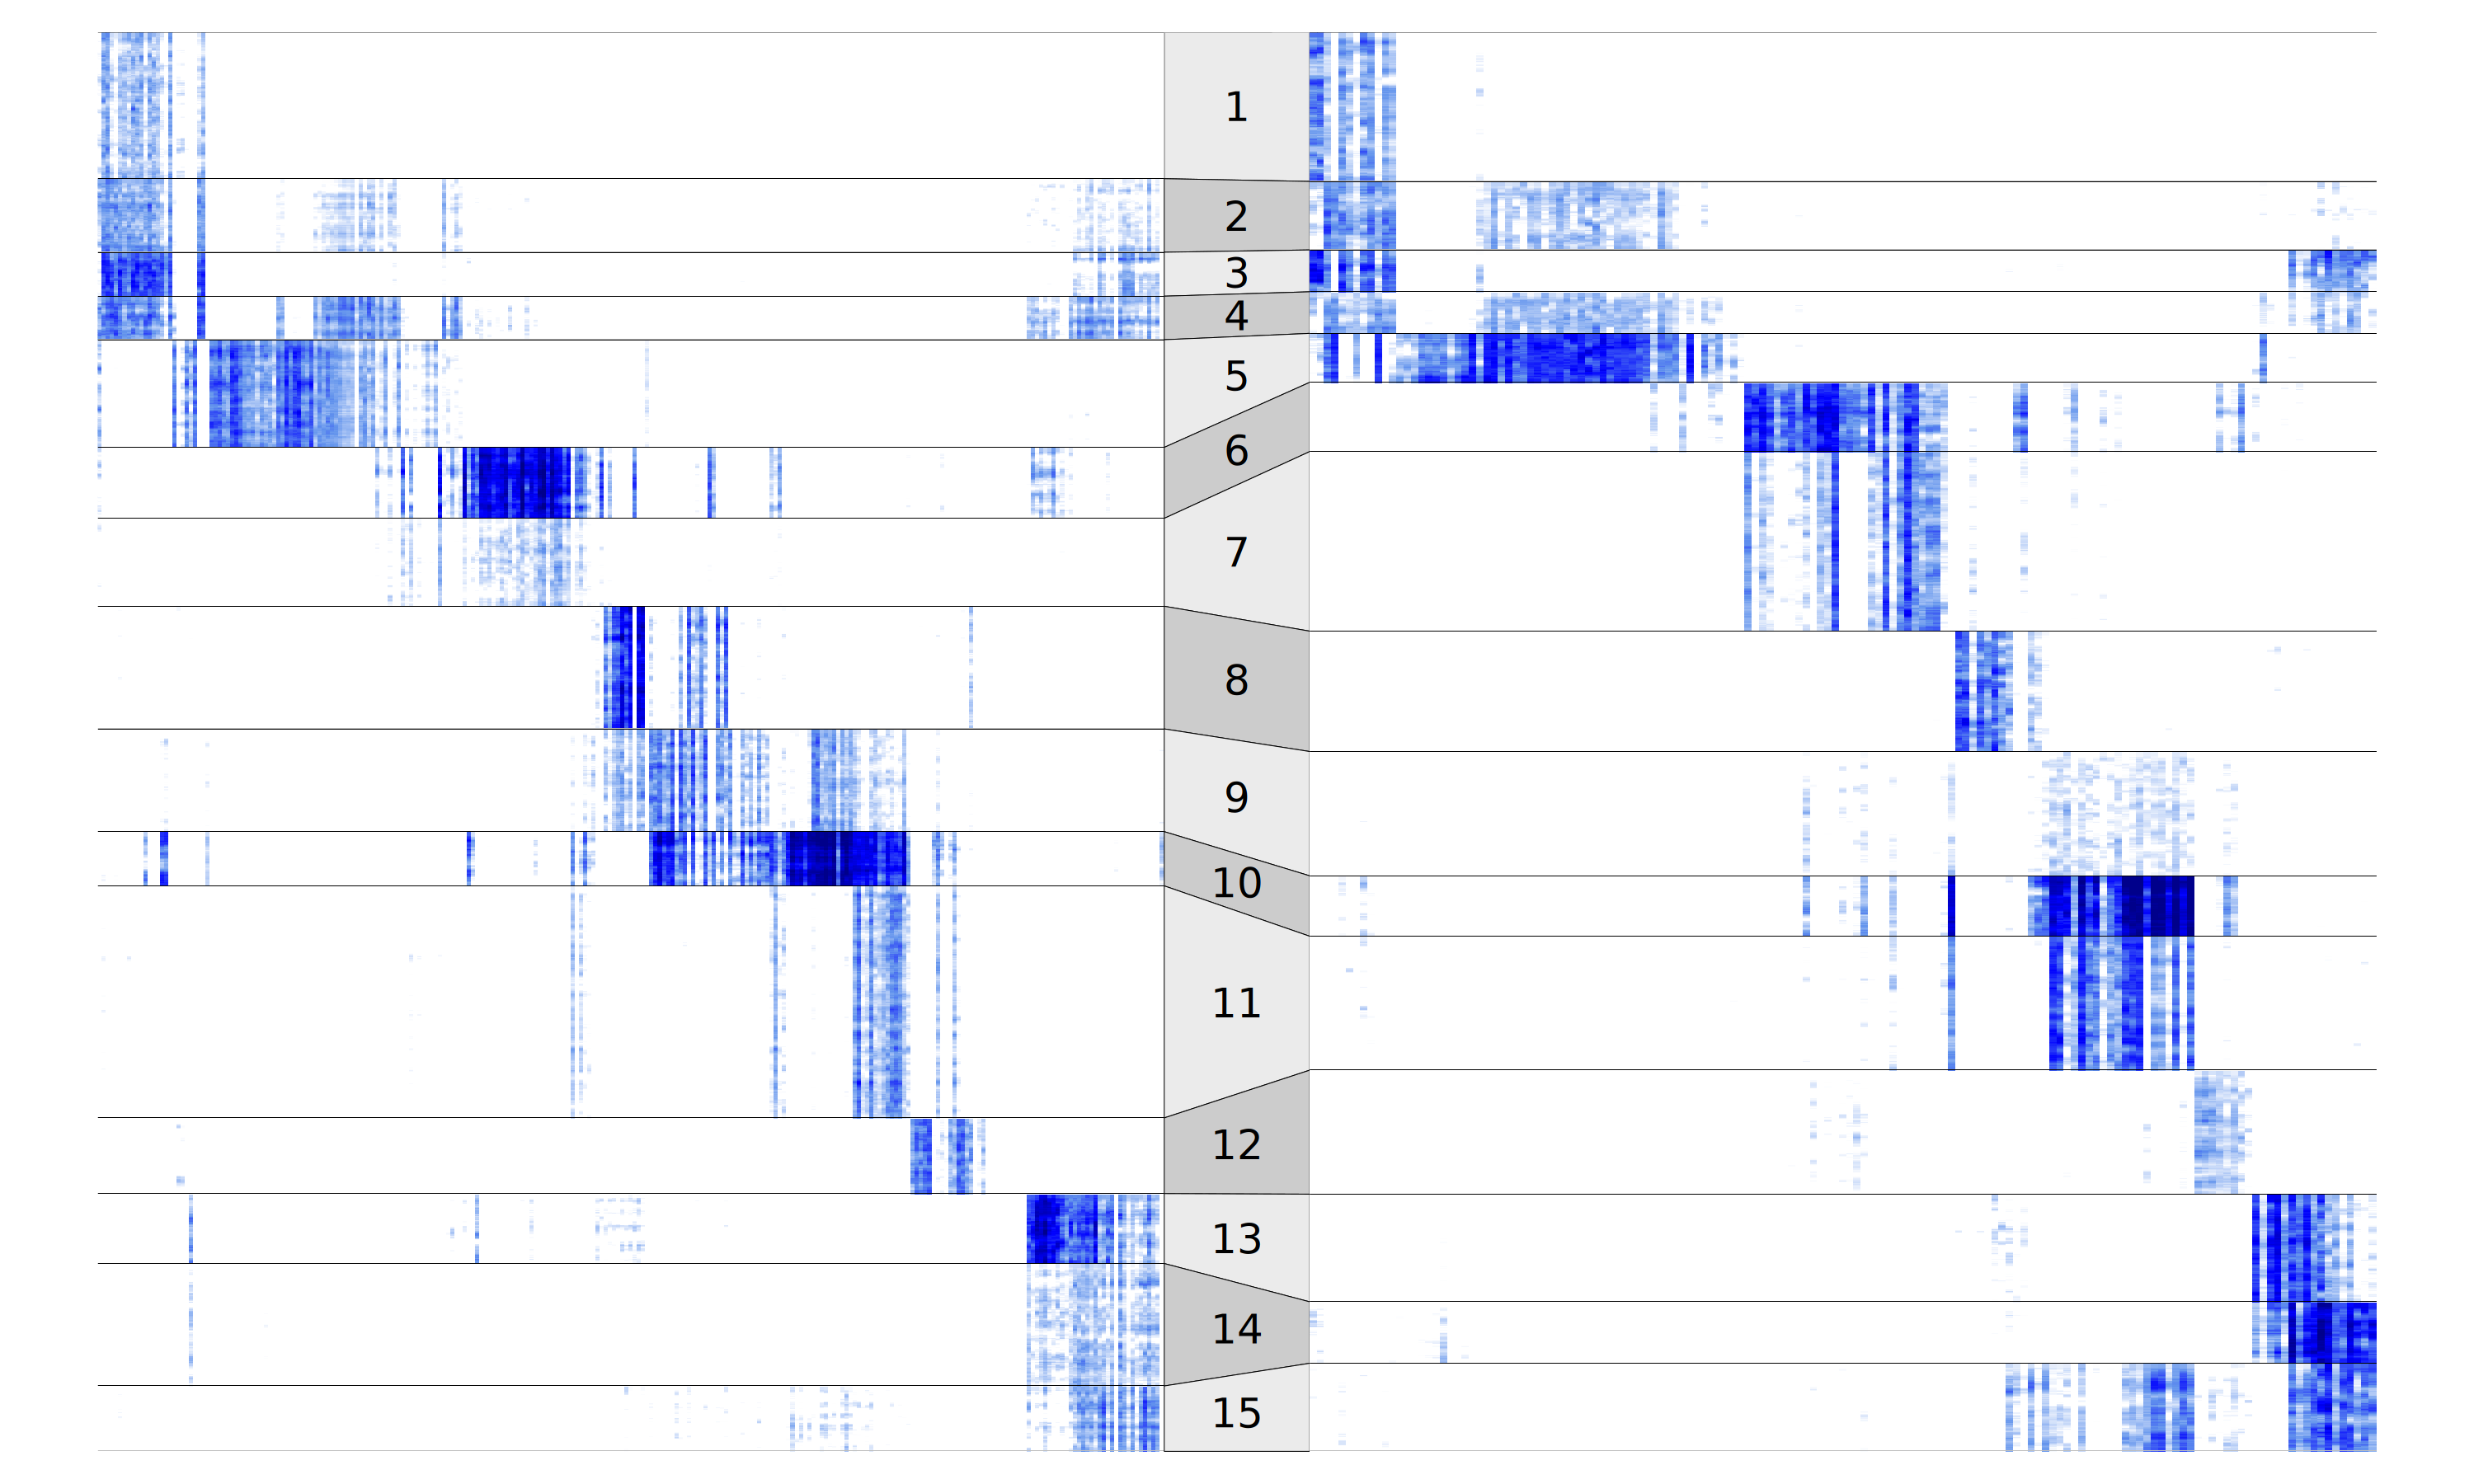

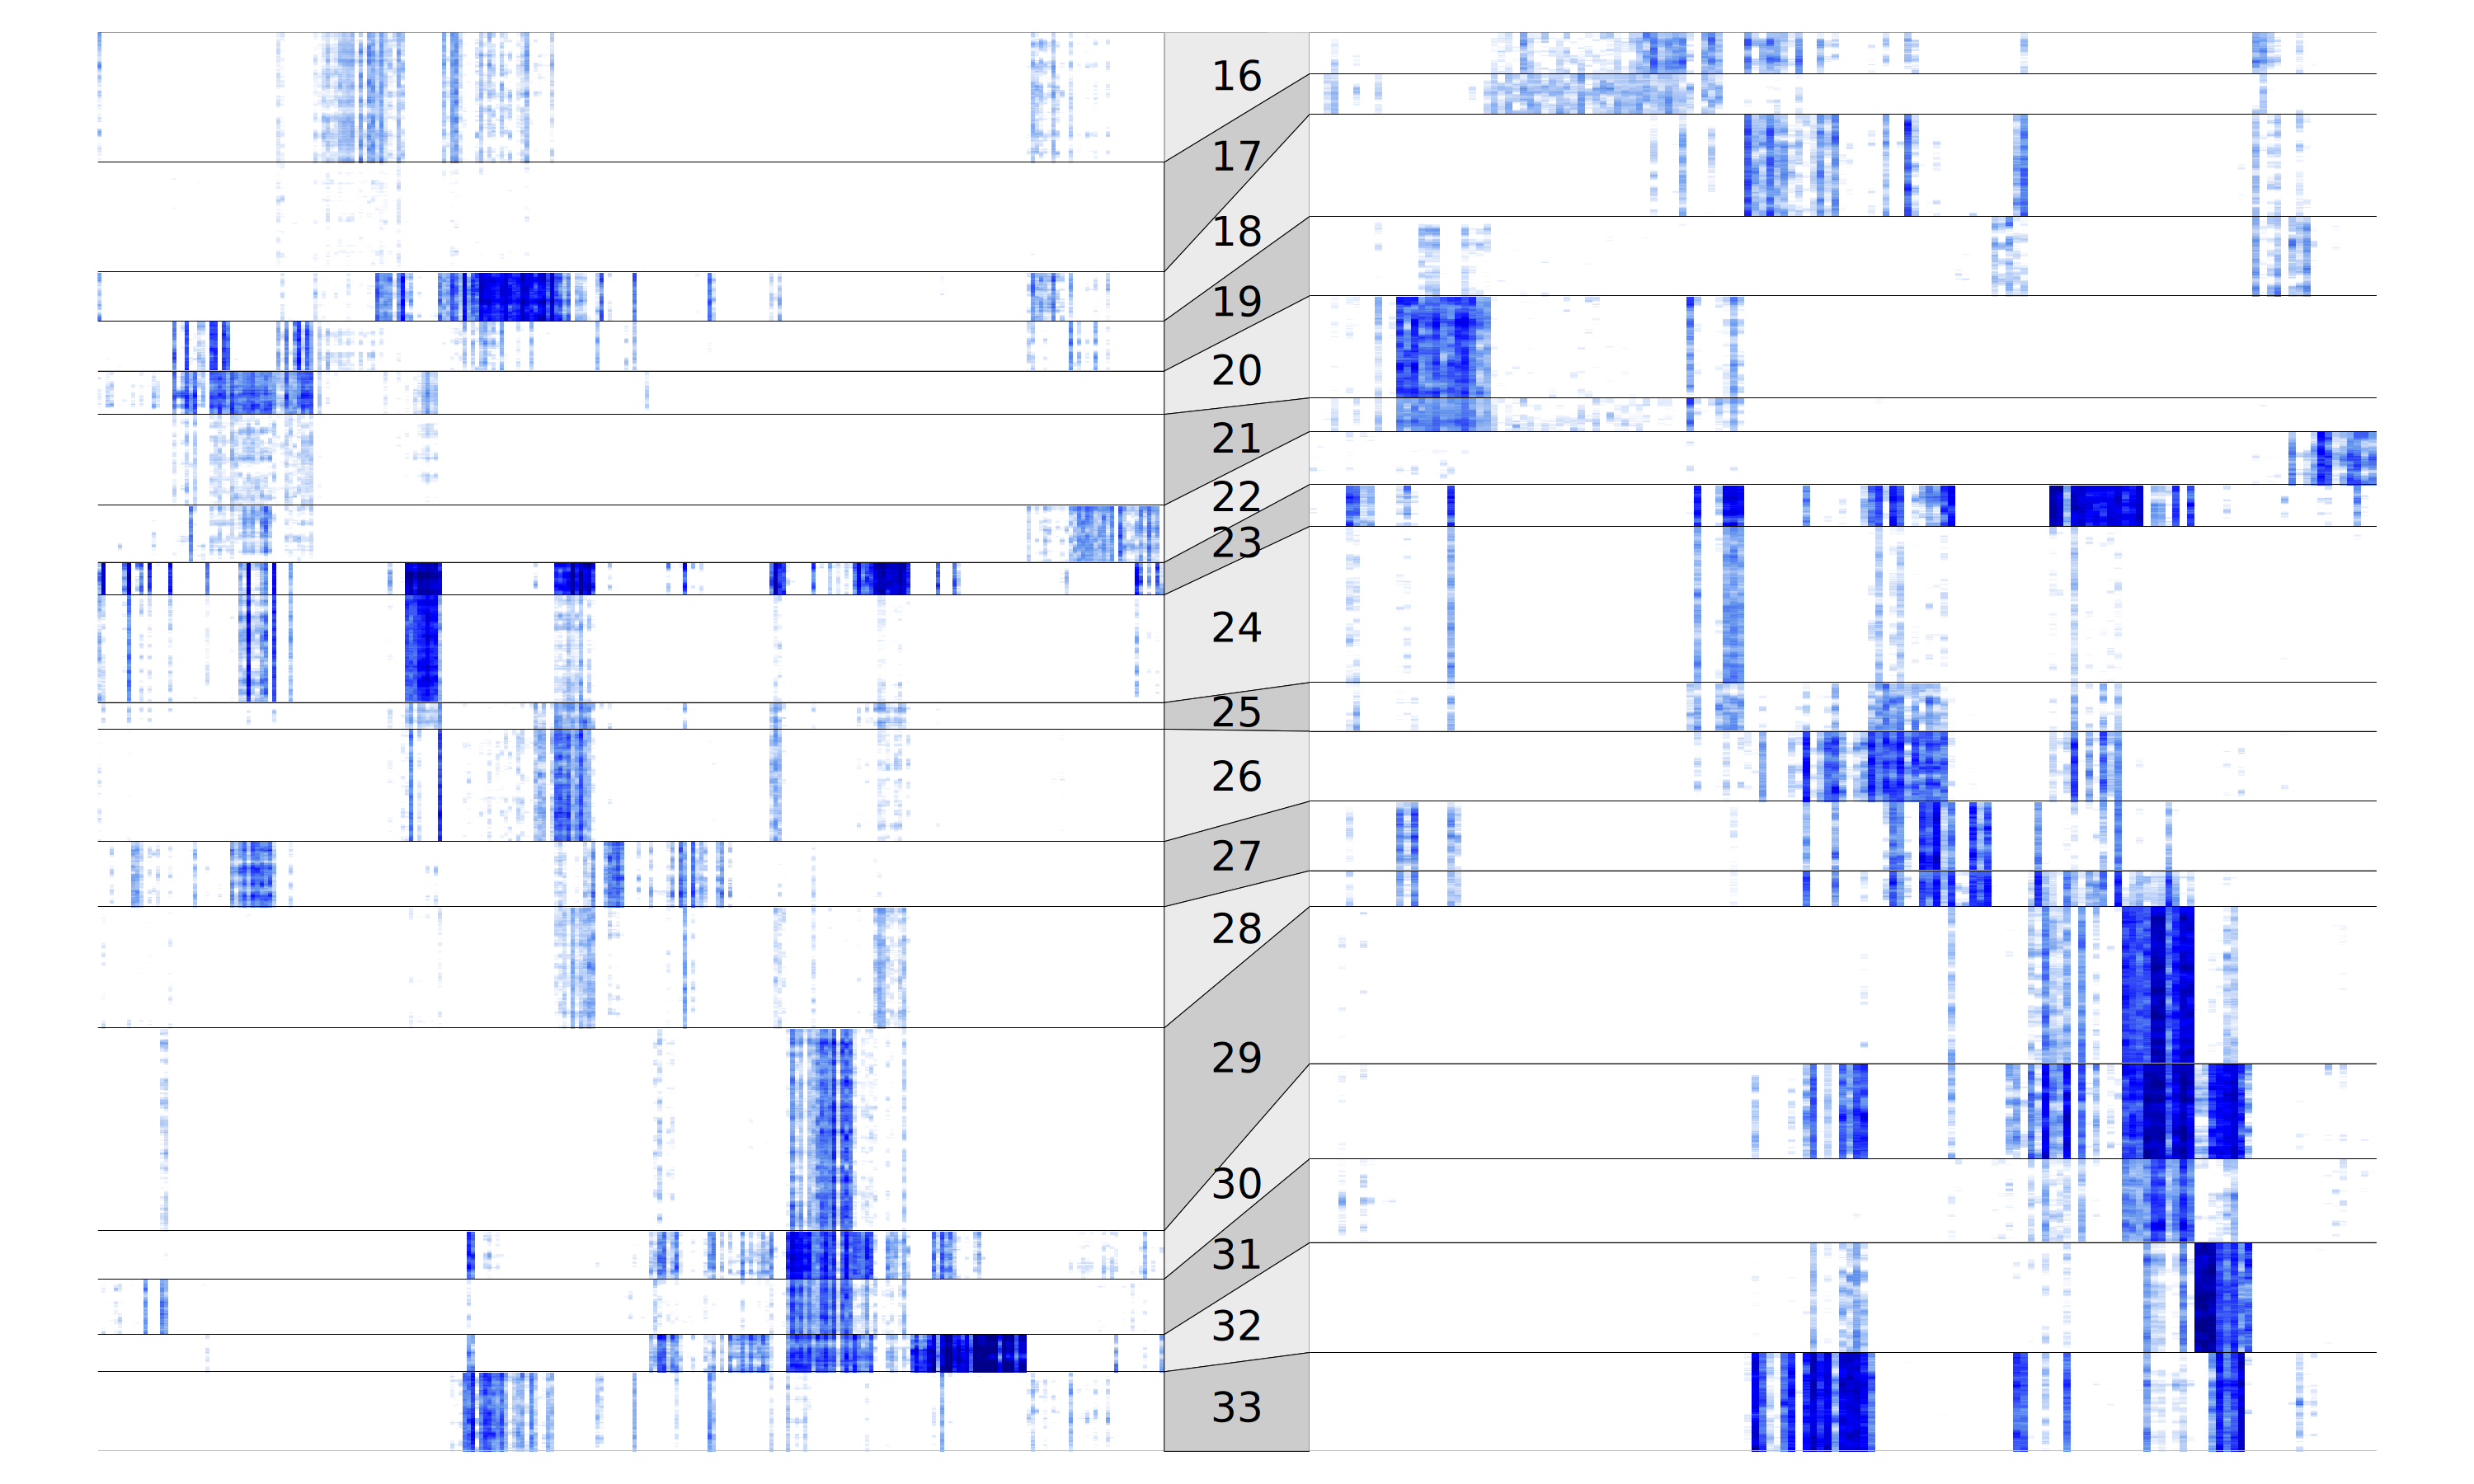

In [8]:
fig1d = function(anchors) {
    mm_vclst_nms = names(anchors)
    mm_f_var_peak = mm_km$cluster %in% mm_vclst_nms
    mm_legc_act_v = mm_a_legc[mm_f_var_peak,]
    mm_map_cls = 1:length(mm_vclst_nms)
    names(mm_map_cls) = mm_vclst_nms
    oc_vclst_nms = unname(anchors)
    oc_f_var_peak = oc_km$cluster %in% oc_vclst_nms
    oc_legc_act_v = oc_a_legc[oc_f_var_peak,]
    oc_map_cls = 1:length(oc_vclst_nms)
    names(oc_map_cls) = oc_vclst_nms

    mm_medians = apply(mm_clst_cent_abs, 1, median)
    oc_medians = apply(oc_clst_cent_abs, 1, median)
    smooth = function(legc_act_v, km, map_cls, ord_clmc, medians) {
        w_size = 30
        first = TRUE
        for(i in rev(names(map_cls))){
            clmat = legc_act_v[as.character(km$cluster[rownames(legc_act_v)]) == i,ord_clmc] - medians[i]
            clmat_sm = clmat
            if (nrow(clmat) > w_size){
                clmat_sm = apply(clmat, 2, function(x) rollmean(x, w_size, na.rm=T, f='e'))
            }
            if(first) {
                mat_sm = clmat_sm
                first = FALSE
            } else {
                mat_sm = rbind(mat_sm, clmat_sm)
            }
        }
        mat_sm
    }
    mm_legc_act_v_sm = smooth(mm_legc_act_v, mm_km, mm_map_cls, mm_ord_clmc, mm_medians)
    oc_legc_act_v_sm = smooth(oc_legc_act_v, oc_km, oc_map_cls, oc_ord_clmc, oc_medians)

    breaks = function(km, f_var_peak, map_cls, fun) tibble::enframe(
        as.character(km$cluster[f_var_peak])[rev(order(map_cls[as.character(km$cluster[f_var_peak])]))]
    ) %>% group_by(value) %>% summarise(pos=fun(name))
    mm_mtext_breaks_max = breaks(mm_km, mm_f_var_peak, mm_map_cls, max)
    mm_mtext_breaks_min = breaks(mm_km, mm_f_var_peak, mm_map_cls, min)
    oc_mtext_breaks_max = breaks(oc_km, oc_f_var_peak, oc_map_cls, max)
    oc_mtext_breaks_min = breaks(oc_km, oc_f_var_peak, oc_map_cls, min)
    mm_mtext_breaks_max = mm_mtext_breaks_max %>% mutate(pos=ifelse(value %in% names(mm_renaming), pos, 0))
    mm_mtext_breaks_min = mm_mtext_breaks_min %>% mutate(pos=ifelse(value %in% names(mm_renaming), pos, 0))
    oc_mtext_breaks_max = oc_mtext_breaks_max %>% mutate(pos=ifelse(value %in% names(oc_renaming), pos, 0))
    oc_mtext_breaks_min = oc_mtext_breaks_min %>% mutate(pos=ifelse(value %in% names(oc_renaming), pos, 0))
    df = mm_mtext_breaks_max %>% mutate(name=ifelse(value %in% names(mm_renaming), mm_renaming[value], '')) %>% arrange(name) %>% select(mm_pos=pos, name) %>%
        left_join(oc_mtext_breaks_max %>% mutate(name=ifelse(value %in% names(oc_renaming), oc_renaming[value], '')) %>% arrange(name) %>% select(oc_pos=pos, name), by = "name") %>%
        mutate(mm_idx=1/length(mm_km$cluster[mm_f_var_peak]) + mm_pos/max(mm_pos)) %>%
        mutate(oc_idx=1/length(oc_km$cluster[oc_f_var_peak]) + oc_pos/max(oc_pos)) %>%
        select(name, mm_idx, oc_idx)
    n = nrow(df)

    abs_shades = colorRampPalette(c("white", "white", "cornflowerblue", "blue", "darkblue", "darkblue"))(1000)
    layout(matrix(1:3, nrow = 1), widths = c(4, 0.5, 4))
    par(mar = c(2, 6, 2, 0))
    image(t(mm_legc_act_v_sm), col = abs_shades, breaks = c(-2, seq(0, 2, l = 999), 3), axes = FALSE)
    abline(h = 1/length(mm_km$cluster[mm_f_var_peak]) + mm_mtext_breaks_min$pos / max(mm_mtext_breaks_max$pos), lwd = 0.5, col = "grey")
    abline(h = 1/length(mm_km$cluster[mm_f_var_peak]) + mm_mtext_breaks_max$pos / max(mm_mtext_breaks_max$pos), lwd = 0.5)
    par(mar = c(2, 0, 2, 0))
    plot.new()
    plot.window(xlim = c(0, 1), ylim = c(0, 1), xaxs = "i", yaxs = "i")
    fills = c("#CCCCCC", "#EBEBEB")
    walk(seq_len(n), function(i) {
        py = c(df$mm_idx[i], df$oc_idx[i], ifelse(i + 1 > n, 0, df$oc_idx[i + 1]), ifelse(i + 1 > n, 0, df$mm_idx[i + 1]))
        polygon(c(0, 1, 1, 0), py, col = fills[(i %% 2) + 1], border = "black", lwd = 0.5)
    })
    walk(seq_len(n), function(i) {
        py = c(df$mm_idx[i], df$oc_idx[i], ifelse(i + 1 > n, 0, df$oc_idx[i + 1]), ifelse(i + 1 > n, 0, df$mm_idx[i + 1]))
        text(0.5, mean(py), labels = df$name[i], cex = 3, font = 4)
    })
    par(mar = c(2, 0, 2, 6))
    image(t(oc_legc_act_v_sm), col = abs_shades, breaks = c(-2, seq(0, 2, l = 999), 3), axes = FALSE)
    abline(h = 1/length(oc_km$cluster[oc_f_var_peak]) + oc_mtext_breaks_min$pos / max(oc_mtext_breaks_max$pos), lwd = 0.5, col = "grey")
    abline(h = 1/length(oc_km$cluster[oc_f_var_peak]) + oc_mtext_breaks_max$pos / max(oc_mtext_breaks_max$pos), lwd = 0.5)
}
options(repr.plot.width = 20, repr.plot.height = 12)
fig1d(matched_1hot_vclust)
fig1d(matched_comb_vclust)

## 7. Fig 1E

Mouse against rabbit accessibility of anchor pairs over the 24 homologous states (step 3), coloured by the type of the
mouse state; r is the Pearson correlation.

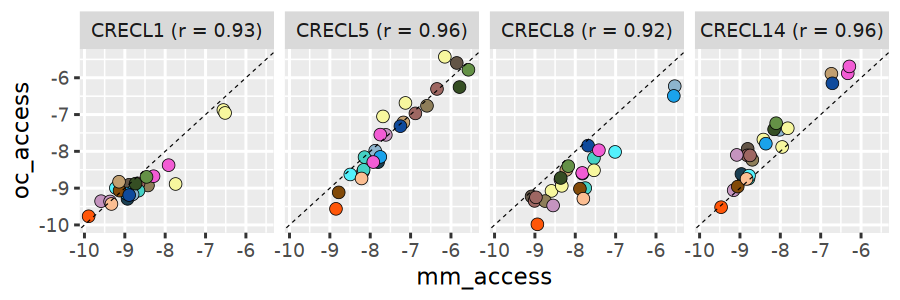

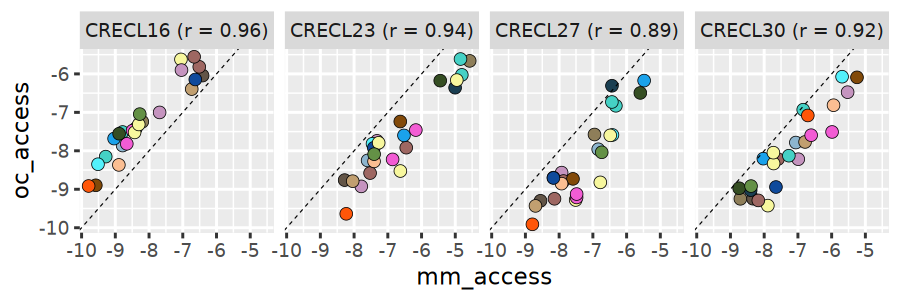

In [9]:
fig1e = function(examples) {
    d = cbind(
        as.data.frame(mm_crecl_sup_legc[rbomcs$mouse_mcc, names(match_rabbit)]) %>%
            rownames_to_column("mm_rbom") %>%
            pivot_longer(!mm_rbom, names_to = "mm_crecl", values_to = "mm_access"),
        as.data.frame(oc_crecl_sup_legc[rbomcs$rabbit_mcc, match_rabbit]) %>%
            rownames_to_column("oc_rbom") %>%
            pivot_longer(!oc_rbom, names_to = "oc_crecl", values_to = "oc_access")
    ) %>%
        filter(mm_crecl %in% examples) %>%
        mutate(mm_crecl = mm_renaming[mm_crecl]) %>%
        mutate(mm_crecl = factor(mm_crecl, levels = mm_renaming[examples])) %>%
        mutate(mm_type = mm_mclst_type[mm_rbom]) %>%
        group_by(mm_crecl) %>%
        mutate(
            r_val = cor(mm_access, oc_access, use = "pairwise.complete.obs"),
            mm_crecl_title = paste0("CRECL",mm_crecl, " (r = ", round(r_val, 2), ")")
        ) %>%
        ungroup() %>%
        mutate(mm_crecl_title = forcats::fct_reorder(mm_crecl_title, as.numeric(mm_crecl)))
    print(d %>%
        ggplot(aes(x = mm_access, y = oc_access, fill = mm_type)) +
        geom_point(shape = 21, color = "black", stroke = 0.2, size = 2.5) +
        facet_wrap(~mm_crecl_title, nrow = 1) +
        scale_fill_manual(values = mm_code_color, breaks = mm_code_color) +
        geom_abline(slope = 1, intercept = 0, lty = 2, lwd = 0.2))
}
example_ontogeneic = c("75","60","97","76")
example_comb = c("34","86","79","8")
options(repr.plot.width = 6, repr.plot.height = 2)
fig1e(example_ontogeneic)
fig1e(example_comb)

## Outputs

For the later notebooks: the CRECl classes (`crecl_classes.csv`), CRECl accessibility by state (`mm_crecl_sup_legc.csv`,
`oc_crecl_sup_legc.csv`), the paper number of every CRECl that joined an anchor (`crecl_numbering.csv`) and the anchor
pairs and CRECl lists (`crecls.rds`).

In [10]:
fwrite(crecl_classes, file.path(out_dir, "crecl_classes.csv"))
fwrite(as.data.frame(mm_crecl_sup_legc) %>% rownames_to_column("mm_supt"), file.path(out_dir, "mm_crecl_sup_legc.csv"))
fwrite(as.data.frame(oc_crecl_sup_legc) %>% rownames_to_column("oc_supt"), file.path(out_dir, "oc_crecl_sup_legc.csv"))
fwrite(crecl_numbering, file.path(out_dir, "crecl_numbering.csv"))
saveRDS(list(match_rabbit = match_rabbit, mm_renaming = mm_renaming, oc_renaming = oc_renaming,
             mm_1hot_vclust = mm_1hot_vclust, oc_1hot_vclust = oc_1hot_vclust,
             mm_comb_vclust = mm_comb_vclust, oc_comb_vclust = oc_comb_vclust,
             mm_const_crecls = mm_const_crecls, oc_const_crecls = oc_const_crecls, crecl_classes = crecl_classes),
        file.path(out_dir, "crecls.rds"))